In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import MeanSquaredError, BinaryCrossentropy
from tensorflow.keras.layers import GRU, Dropout, Dense, Bidirectional
from tensorflow.keras.models import Sequential
from sklearn.metrics import  mean_squared_error, mean_absolute_error, mean_absolute_percentage_error
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import MinMaxScaler, StandardScaler, LabelEncoder
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import time
from tqdm import tqdm
import os
import random
import pickle
import warnings
warnings.filterwarnings("ignore")
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
def dataori(seq_len):
  data_path = "/content/drive/MyDrive/suplemen.csv"
  df = pd.read_csv(data_path)

  # Label Encoding
  itemL = LabelEncoder()
  platL = LabelEncoder()

  df['ItemID_Encoded'] = itemL.fit_transform(df['Product Name'])
  df['PlatformID_Encoded'] = platL.fit_transform(df['Platform'])
  features = ['Units Sold', 'Price', 'Revenue', 'Discount', 'Units Returned', 'ItemID_Encoded', 'PlatformID_Encoded']
  df_clean = df[features].dropna()

  split = int(len(df_clean) * 0.8)
  train = df_clean.iloc[:split]
  test = df_clean.iloc[split:]
  train_a = train.to_numpy()
  test_a = test.to_numpy()

  scaler = MinMaxScaler()
  train_norm = scaler.fit_transform(train_a)
  test_norm = scaler.transform(test_a)

  # Create sequences
  data = []
  for i in range(len(train_norm) - seq_len):
    data.append(train_norm[i:i + seq_len])
  data = np.array(data)

  print(f"Train: {len(train)}")
  print(f"Test: {len(test)}")
  print(f"Sequence shape: {data.shape}")

  with open("/content/drive/MyDrive/itemL_encoder.pkl", "wb") as f:
    pickle.dump(itemL, f)

  with open("/content/drive/MyDrive/platL_encoder.pkl", "wb") as f:
    pickle.dump(platL, f)

  # Save scaler
  with open("/content/drive/MyDrive/scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

  return data, test_norm, scaler, train_norm, itemL, platL

seq_len=13
data, test_norm, scaler, train_norm, itemL, platL = dataori(seq_len)

In [ ]:
# Class TimeGAN
class Embedder(tf.keras.Model):
  def __init__(self, hidden_dim, num_layers):
    super(Embedder, self).__init__()
    self.rnn_layers = [GRU(hidden_dim, return_sequences=True, activation='tanh') for _ in range(num_layers)]
    self.dense = tf.keras.layers.Dense(hidden_dim, activation='sigmoid')

  def call(self, x):
    for rnn in self.rnn_layers:
      x = rnn(x)
    return self.dense(x)

class Generator(tf.keras.Model):
  def __init__(self, hidden_dim, num_layers):
    super(Generator, self).__init__()
    self.rnn_layers = [GRU(hidden_dim, return_sequences=True, activation='tanh') for _ in range(num_layers)]
    self.dense = tf.keras.layers.Dense(hidden_dim, activation='sigmoid')

  def call(self, x):
    for rnn in self.rnn_layers:
      x = rnn(x)
    return self.dense(x)

class Supervisor(tf.keras.Model):
  def __init__(self, hidden_dim, num_layers):
    super(Supervisor, self).__init__()
    self.rnn_layers = [GRU(hidden_dim, return_sequences=True, activation='tanh') for _ in range(num_layers - 1)]
    self.dense = tf.keras.layers.Dense(hidden_dim, activation='sigmoid')

  def call(self, x):
    for rnn in self.rnn_layers:
      x = rnn(x)
    return self.dense(x)

class Recovery(tf.keras.Model):
  def __init__(self, hidden_dim, original_dim, num_layers):
    super(Recovery, self).__init__()
    self.rnn_layers = [GRU(hidden_dim, return_sequences=True, activation='tanh') for _ in range(num_layers)]
    self.dense = tf.keras.layers.Dense(original_dim, activation='sigmoid')

  def call(self, x):
    for rnn in self.rnn_layers:
      x = rnn(x)
    return self.dense(x)

class Discriminator(tf.keras.Model):
  def __init__(self, hidden_dim, num_layers):
    super(Discriminator, self).__init__()
    self.rnn_layers = [Bidirectional(GRU(hidden_dim, return_sequences=True, activation='tanh')) for _ in range(num_layers)]
    self.dense = tf.keras.layers.Dense(1, activation=None)

  def call(self, h, mask=None):
    x = h
    for rnn in self.rnn_layers:
      x = rnn(x, mask=mask)
    return self.dense(x)

In [ ]:
def timegan(train_data, parameters, use_checkpoint=True):
  total_start = time.time()
  hidden_dim = parameters['hidden_dim']
  num_layers = parameters['num_layer']
  batch_size = parameters['batch_size']
  iterations = parameters['iterations']
  learning_rate = parameters['learning_rate']
  gamma = parameters['gamma']
  z_dim = parameters.get('z_dim', hidden_dim)

  no, seq_len, dim = train_data.shape

  # Inisialisasi model
  embedder = Embedder(hidden_dim, num_layers)
  recovery = Recovery(hidden_dim, dim, num_layers)
  generator = Generator(hidden_dim, num_layers)
  supervisor = Supervisor(hidden_dim, num_layers)
  discriminator = Discriminator(hidden_dim, num_layers)

  # Optimizer
  e_optimizer = Adam(learning_rate)
  g_optimizer = Adam(learning_rate)
  s_optimizer = Adam(learning_rate)
  d_optimizer = Adam(learning_rate)

  mse = MeanSquaredError()

  models = {
      "embedder": embedder,
      "recovery": recovery,
      "generator": generator,
      "supervisor": supervisor,
      "discriminator": discriminator
  }

  def format_duration(seconds):
    hrs, rem = divmod(int(seconds), 3600)
    mins, secs = divmod(rem, 60)
    return f"{hrs:02d}:{mins:02d}:{secs:02d}"

  def batch_generator(data, batch_size):
    idx = np.random.permutation(len(data))[:batch_size]
    return data[idx]

  def random_generator(batch_size, z_dim, seq_len):
    return tf.random.normal(shape=(batch_size, seq_len, z_dim))

  def add_instance_noise(x, stddev=0.1):
    return x + tf.random.normal(tf.shape(x), mean=0.0, stddev=stddev)

  def moment_loss(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    true_mean, true_var = tf.nn.moments(y_true, axes=[0])
    pred_mean, pred_var = tf.nn.moments(y_pred, axes=[0])
    mean_loss = tf.reduce_mean(tf.abs(true_mean - pred_mean))
    std_loss = tf.reduce_mean(tf.abs(tf.sqrt(true_var + 1e-6) - tf.sqrt(pred_var + 1e-6)))
    return mean_loss + std_loss

  # Set seed
  SEED = 32
  random.seed(SEED)
  np.random.seed(SEED)
  tf.random.set_seed(SEED)

  @tf.function
  def train_embedder(X):
    with tf.GradientTape() as tape:
      H = embedder(X)
      X_tilde = recovery(H)
      H_hat = supervisor(H)
      G_loss_S = mse(H[:, 1:, :], H_hat[:, :-1, :])
      E_loss_T0 = mse(X, X_tilde)
      E_loss = 10 * tf.sqrt(E_loss_T0) + 0.1 * G_loss_S

    var_list = embedder.trainable_variables + recovery.trainable_variables
    grads = tape.gradient(E_loss, var_list)
    e_optimizer.apply_gradients(zip(grads, var_list))
    return E_loss

  @tf.function
  def train_supervisor(X):
    with tf.GradientTape() as tape:
      H = embedder(X)
      H_hat = supervisor(H)
      G_loss_S = mse(H[:, 1:, :], H_hat[:, :-1, :])

    var_list = supervisor.trainable_variables
    grads = tape.gradient(G_loss_S, var_list)
    s_optimizer.apply_gradients(zip(grads, var_list))
    return G_loss_S

  @tf.function
  def train_generator(Z, X_real):
    with tf.GradientTape() as tape:
      E_hat = generator(Z)
      H_hat = supervisor(E_hat)
      X_hat = recovery(H_hat)
      Y_fake = discriminator(H_hat)
      Y_fake_e = discriminator(E_hat)
      G_loss_U = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(logits=Y_fake, labels=tf.ones_like(Y_fake)))
      G_loss_U_E = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(logits=Y_fake, labels=tf.ones_like(Y_fake_e)))
      G_loss_S = mse(E_hat[:, 1:, :], H_hat[:, :-1, :])
      G_loss_V = moment_loss(X_real, X_hat)
      G_loss = G_loss_U + G_loss_U_E + 100 * tf.sqrt(G_loss_S) + 300 * G_loss_V

    var_list = generator.trainable_variables + supervisor.trainable_variables
    grads = tape.gradient(G_loss, var_list)
    g_optimizer.apply_gradients(zip(grads, var_list))
    return G_loss, G_loss_U, G_loss_S, G_loss_V

  @tf.function
  def train_discriminator(H, H_hat, E_hat):
    with tf.GradientTape() as tape:
      Y_real = discriminator(add_instance_noise(H))
      Y_fake = discriminator(add_instance_noise(H_hat))
      Y_fake_e = discriminator(add_instance_noise(E_hat))
      real_labels = tf.ones_like(Y_real)
      fake_labels = tf.zeros_like(Y_fake)
      D_loss_real = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(logits=Y_real, labels=real_labels))
      D_loss_fake = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(logits=Y_fake, labels=fake_labels))
      D_loss_fake_e = tf.reduce_mean(tf.nn.sigmoid_cross_entropy_with_logits(logits=Y_fake_e, labels=fake_labels))
      D_loss = D_loss_real + D_loss_fake + gamma * D_loss_fake_e

    grads = tape.gradient(D_loss, discriminator.trainable_variables)
    d_optimizer.apply_gradients(zip(grads, discriminator.trainable_variables))
    return D_loss

  print("Pretraining Embedder")
  with open("Log Pretrain Embedder.txt", "w") as f:
    pre1_start = time.time()
    for step in tqdm(range(iterations), desc="Pretraining Embedder"):
      X_mb = batch_generator(train_data, batch_size)
      E_loss = train_embedder(X_mb)
      if step % 1000 == 0:
          log_loss1=f"Step: {step}, E_loss: {E_loss.numpy():.4f}"
          f.write(log_loss1 + "\n")
    pre1_end = time.time()
    durasi1 = format_duration(pre1_end - pre1_start)
    print(f"[Embedder Time] {durasi1}")
    f.write(f"[Embedder Time] {durasi1}")

  print("Pretraining Supervisor")
  with open("Log Pretrain Supervisor.txt", "w") as f:
    pre2_start = time.time()
    for step in tqdm(range(iterations), desc="Pretraining Supervisor"):
      X_mb = batch_generator(train_data, batch_size)
      G_loss_S = train_supervisor(X_mb)
      if step % 1000 == 0:
        log_loss2=f"Step: {step}, G_loss_S: {G_loss_S.numpy():.4f}"
        f.write(log_loss2 + "\n")
    pre2_end = time.time()
    durasi2 = format_duration(pre2_end - pre2_start)
    print(f"[Embedder Time] {durasi2}")
    f.write(f"[Embedder Time] {durasi2}")

  print("Joint Training")
  with open("Log Joint Training.txt", "a") as f:
    joint_start = time.time()
    for step in tqdm(range(iterations), desc="Joint Training"):
      for _ in range(1):
        X_mb = batch_generator(train_data, batch_size)
        train_embedder(X_mb)
        train_supervisor(X_mb)

      for _ in range(2):
        X_mb = batch_generator(train_data, batch_size)
        Z_mb = random_generator(batch_size, z_dim, seq_len)
        G_loss, G_loss_U, G_loss_S, G_loss_V = train_generator(Z_mb, X_mb)

      for _ in range(1):
        X_mb = batch_generator(train_data, batch_size)
        Z_mb = random_generator(batch_size, z_dim, seq_len)
        H = embedder(X_mb)
        E_hat = generator(Z_mb)
        H_hat = supervisor(E_hat)
        D_loss = train_discriminator(H, H_hat, E_hat)

      if step % 1000 == 0 or step == iterations - 1:
        log_loss3=f"Step: {step}, G_loss: {G_loss.numpy():.4f}, G_loss_U: {G_loss_U.numpy():.4f}, G_loss_S: {G_loss_S.numpy():.6f}, G_loss_V: {G_loss_V.numpy():.4f}, D_loss: {D_loss.numpy():.4f}"
        f.write(log_loss3 + "\n")


    joint_end = time.time()
    durasi3 = format_duration(joint_end - joint_start)

    print(f"[Joint Training Time] {durasi3}")
    f.write(f"[Joint Training Time] {durasi3}")

  print(f"[Total Training Time] {format_duration(time.time() - total_start)}")

  return models

def generate_synthetic_data(generator, supervisor, recovery, z_dim, seq_len, dim, n_samples):
  Z = np.random.uniform(-1, 1, size=(n_samples, seq_len, z_dim)).astype(np.float32)
  E_hat = generator(Z)
  H_hat = supervisor(E_hat)
  X_hat = recovery(H_hat)
  return X_hat.numpy()

In [ ]:
parameters = {
    'module': 'gru',
    'hidden_dim': 64,
    'num_layer': 4,
    'iterations': 10000,
    'batch_size': 128,
    'learning_rate': 5e-4,
    'gamma': 0.01
}

models = timegan(data, parameters)
embedder = models["embedder"]
recovery = models["recovery"]
generator = models["generator"]
supervisor = models["supervisor"]
discriminator = models["discriminator"]

sintetis = generate_synthetic_data(
    generator=generator,
    supervisor=supervisor,
    recovery=recovery,
    z_dim=parameters['hidden_dim'],
    seq_len=data.shape[1],
    dim=data.shape[2],
    n_samples=data.shape[0]
)

# Save data sintetis
np.save("/content/drive/MyDrive/data_sintetis.npy", sintetis)

pd.DataFrame(sintetis.reshape(sintetis.shape[0], -1)).to_csv(
    "/content/drive/MyDrive/data_sintetis.csv", index=False
)

print("Sintetis shape:", sintetis.shape)

Pretraining Embedder


Pretraining Embedder: 100%|██████████| 10000/10000 [02:57<00:00, 56.41it/s]


[Embedder Time] 00:02:57
Pretraining Supervisor


Pretraining Supervisor: 100%|██████████| 10000/10000 [01:14<00:00, 133.90it/s]


[Embedder Time] 00:01:14
Joint Training


Joint Training: 100%|██████████| 10000/10000 [30:42<00:00,  5.43it/s]


[Joint Training Time] 00:30:42
[Total Training Time] 00:34:54
Sintetis shape: (3494, 13, 7)


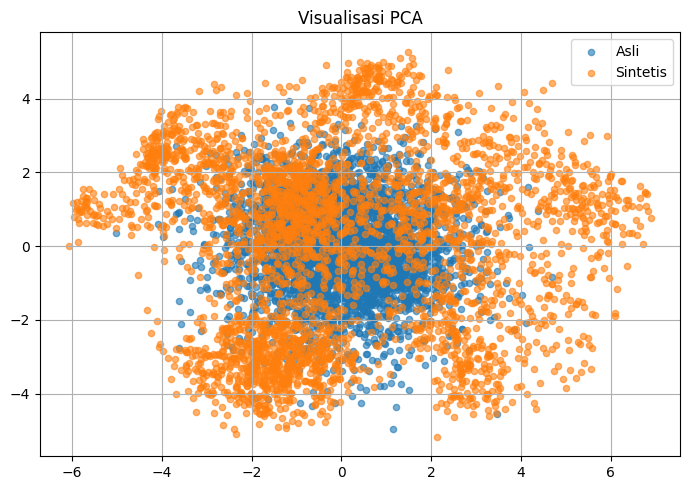

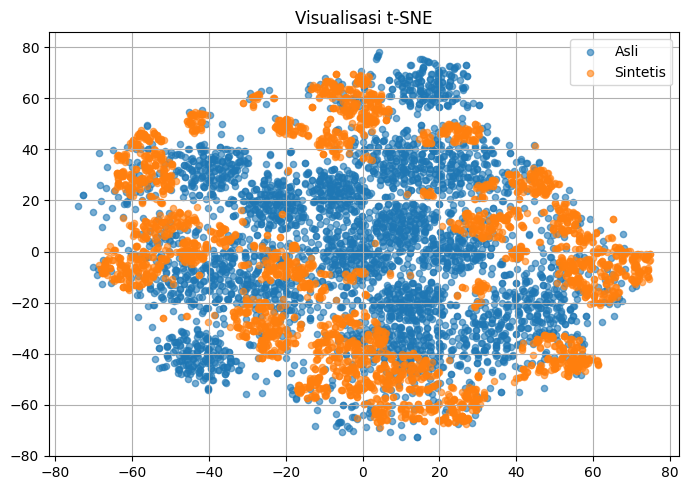

In [ ]:
def pca_visualization(real_data, synthetic_data):
  # Ambil shape masing-masing
  n_real, t, d = real_data.shape
  n_synth, _, _ = synthetic_data.shape
  # Flatten
  real_flatten = real_data.reshape((n_real, t * d))
  synth_flatten = synthetic_data.reshape((n_synth, t * d))
  # Gabungkan data
  combined = np.concatenate((real_flatten, synth_flatten), axis=0)
  # Jalankan PCA
  pca = PCA(n_components=2)
  scaler = StandardScaler()
  combined_scaled = scaler.fit_transform(combined)
  embedded = pca.fit_transform(combined_scaled)
  # Pisahkan hasil
  real_embedded = embedded[:n_real]
  synth_embedded = embedded[n_real:]
  # Plot
  plt.figure(figsize=(7, 5))
  plt.scatter(real_embedded[:, 0], real_embedded[:, 1], alpha=0.6, label='Asli', s=20)
  plt.scatter(synth_embedded[:, 0], synth_embedded[:, 1], alpha=0.6, label='Sintetis', s=20)
  plt.title("Visualisasi PCA")
  plt.legend()
  plt.grid(True)
  plt.tight_layout()
  plt.show()

def tsne_visualization(real_data, synthetic_data):
  # Ambil shape masing-masing
  n_real, t, d = real_data.shape
  n_synth, _, _ = synthetic_data.shape
  # Flatten
  real_flatten = real_data.reshape((n_real, t * d))
  synth_flatten = synthetic_data.reshape((n_synth, t * d))
  # Gabungkan data
  combined = np.concatenate((real_flatten, synth_flatten), axis=0)
  # Jalankan t-SNE
  tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, random_state=42)
  scaler = StandardScaler()
  combined_scaled = scaler.fit_transform(combined)
  embedded = tsne.fit_transform(combined_scaled)
  # Pisahkan hasil
  real_embedded = embedded[:n_real]
  synth_embedded = embedded[n_real:]
  # Plot
  plt.figure(figsize=(7, 5))
  plt.scatter(real_embedded[:, 0], real_embedded[:, 1], alpha=0.6, label='Asli', s=20)
  plt.scatter(synth_embedded[:, 0], synth_embedded[:, 1], alpha=0.6, label='Sintetis', s=20)
  plt.title("Visualisasi t-SNE")
  plt.legend()
  plt.grid(True)
  plt.tight_layout()
  plt.show()

pca_visualization(real_data=data, synthetic_data=sintetis)
tsne_visualization(data, sintetis)

In [ ]:
# ============================================================
# SAVE SYNTHETIC DATA IN READABLE FORMAT
# ============================================================
import pandas as pd
import numpy as np
import pickle

# Load synthetic data from CSV
sin_path = "/content/drive/MyDrive/data_sintetis.csv"
sintetis_df = pd.read_csv(sin_path)

print(f"Original CSV shape: {sintetis_df.shape}")
# (3494, 91)

# ============================================================
# Option A: Save flat version (45422 rows × 7 columns)
# ============================================================
print("\n📊 Option A: Creating flat version...")

# Convert DataFrame to NumPy array, then reshape
sintetis_flat = sintetis_df.values.reshape(-1, 7)
#                           ↑
#                    .values fixes the error!

print(f"Flat shape: {sintetis_flat.shape}")
# (45422, 7)

# Create DataFrame with proper column names
df_flat = pd.DataFrame(sintetis_flat,
                       columns=['Units Sold', 'Price', 'Revenue',
                               'Discount', 'Units Returned', 'ItemID', 'PlatformID'])

# Save flat version
df_flat.to_csv("/content/drive/MyDrive/data_sintetis_flat.csv", index=False)
print("✅ Saved: data_sintetis_flat.csv")
print(f"   Shape: {df_flat.shape} - Easy to read in Excel!")

# ============================================================
# Option B: Denormalize first, then save (Real values!)
# ============================================================
print("\n📊 Option B: Creating denormalized version...")

# Load scaler
with open("/content/drive/MyDrive/scaler.pkl", "rb") as f:
    scaler = pickle.load(f)
print("✓ Loaded scaler")

# Denormalize (convert from [0,1] back to original scale)
sintetis_denorm = scaler.inverse_transform(sintetis_flat)
print(f"Denormalized shape: {sintetis_denorm.shape}")

# Create DataFrame with real values
df_denorm = pd.DataFrame(sintetis_denorm,
                         columns=['Units Sold', 'Price', 'Revenue',
                                 'Discount', 'Units Returned', 'ItemID', 'PlatformID'])

# Round ItemID and PlatformID to integers
df_denorm['ItemID'] = np.clip(np.round(df_denorm['ItemID']), 0, 15).astype(int)
df_denorm['PlatformID'] = np.clip(np.round(df_denorm['PlatformID']), 0, 2).astype(int)

# Save denormalized version
df_denorm.to_csv("/content/drive/MyDrive/data_sintetis_readable.csv", index=False)
print("✅ Saved: data_sintetis_readable.csv")
print(f"   Shape: {df_denorm.shape} - Real values, not normalized!")

# ============================================================
# Option C: BONUS - Denormalized with Product/Platform Names
# ============================================================
print("\n📊 Option C (BONUS): Creating version with names...")

# Load encoders
with open("/content/drive/MyDrive/itemL_encoder.pkl", "rb") as f:
    itemL = pickle.load(f)
with open("/content/drive/MyDrive/platL_encoder.pkl", "rb") as f:
    platL = pickle.load(f)
print("✓ Loaded encoders")

# Decode ItemID and PlatformID to names
df_with_names = df_denorm.copy()
df_with_names['Product Name'] = itemL.inverse_transform(df_denorm['ItemID'])
df_with_names['Platform'] = platL.inverse_transform(df_denorm['PlatformID'])

# Reorder columns (names first)
df_with_names = df_with_names[['Product Name', 'Platform', 'Units Sold', 'Price',
                                'Revenue', 'Discount', 'Units Returned', 'ItemID', 'PlatformID']]

# Save version with names
df_with_names.to_csv("/content/drive/MyDrive/data_sintetis_with_names.csv", index=False)
print("✅ Saved: data_sintetis_with_names.csv")
print(f"   Shape: {df_with_names.shape} - MOST READABLE! ⭐")

# ============================================================
# SUMMARY & PREVIEW
# ============================================================
print("\n" + "="*60)
print("SUMMARY OF OUTPUT FILES")
print("="*60)

print("\n1️⃣ data_sintetis_flat.csv")
print(f"   - Shape: {df_flat.shape}")
print(f"   - Values: Normalized [0, 1]")
print(f"   - Preview:")
print(df_flat.head(3))

print("\n2️⃣ data_sintetis_readable.csv")
print(f"   - Shape: {df_denorm.shape}")
print(f"   - Values: Real scale (denormalized)")
print(f"   - Preview:")
print(df_denorm.head(3))

print("\n3️⃣ data_sintetis_with_names.csv ⭐ BEST FOR EXCEL")
print(f"   - Shape: {df_with_names.shape}")
print(f"   - Values: Real scale + Product/Platform names")
print(f"   - Preview:")
print(df_with_names.head(3))

print("\n" + "="*60)
print("🎉 ALL VERSIONS SAVED SUCCESSFULLY!")
print("="*60)
print("Recommendation: Use 'data_sintetis_with_names.csv' for Excel analysis!")

Original CSV shape: (3494, 91)

📊 Option A: Creating flat version...
Flat shape: (45422, 7)
✅ Saved: data_sintetis_flat.csv
   Shape: (45422, 7) - Easy to read in Excel!

📊 Option B: Creating denormalized version...
✓ Loaded scaler
Denormalized shape: (45422, 7)
✅ Saved: data_sintetis_readable.csv
   Shape: (45422, 7) - Real values, not normalized!

📊 Option C (BONUS): Creating version with names...
✓ Loaded encoders
✅ Saved: data_sintetis_with_names.csv
   Shape: (45422, 9) - MOST READABLE! ⭐

SUMMARY OF OUTPUT FILES

1️⃣ data_sintetis_flat.csv
   - Shape: (45422, 7)
   - Values: Normalized [0, 1]
   - Preview:
   Units Sold     Price   Revenue  Discount  Units Returned    ItemID  \
0    0.720822  0.872079  0.795157  0.120375        0.097535  0.412023   
1    0.454523  0.741649  0.593406  0.579213        0.080405  0.182641   
2    0.673973  0.952336  0.850710  0.543803        0.347846  0.659004   

   PlatformID  
0    0.511515  
1    0.999910  
2    0.999766  

2️⃣ data_sintetis_read

Selected Product: Pre-Workout (ItemID: 12)

Filtered data for Pre-Workout:
  Train: (219, 7)
  Test: (55, 7)
  Synthetic: (3008, 7)

Training: Pre-Workout - Amazon
Training Baseline Model...
Training Augmented Model...

Training: Pre-Workout - Walmart
Training Baseline Model...
Training Augmented Model...

Training: Pre-Workout - iHerb
Training Baseline Model...
Training Augmented Model...
Platform Base_MAPE Base_MAE Base_RMSE Aug_MAPE Aug_MAE Aug_RMSE
  Amazon     9.07%    13.82     16.68    7.06%   10.76    13.12
 Walmart     5.95%     9.10     12.44    9.97%   15.76    19.38
   iHerb    11.55%    16.86     20.44    9.27%   13.43    16.40
 OVERALL     9.05%    13.52     17.13    8.80%   13.32    16.49


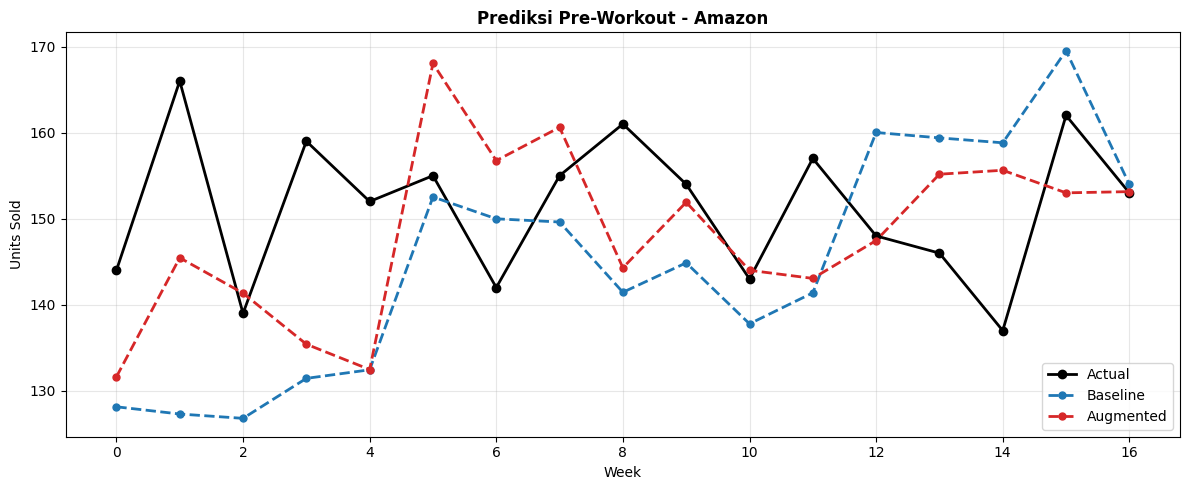

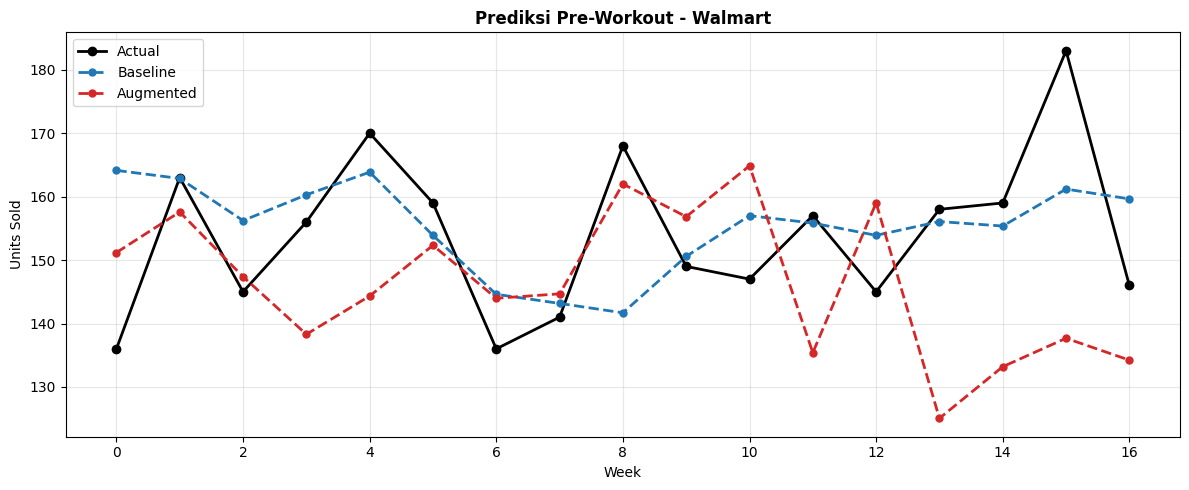

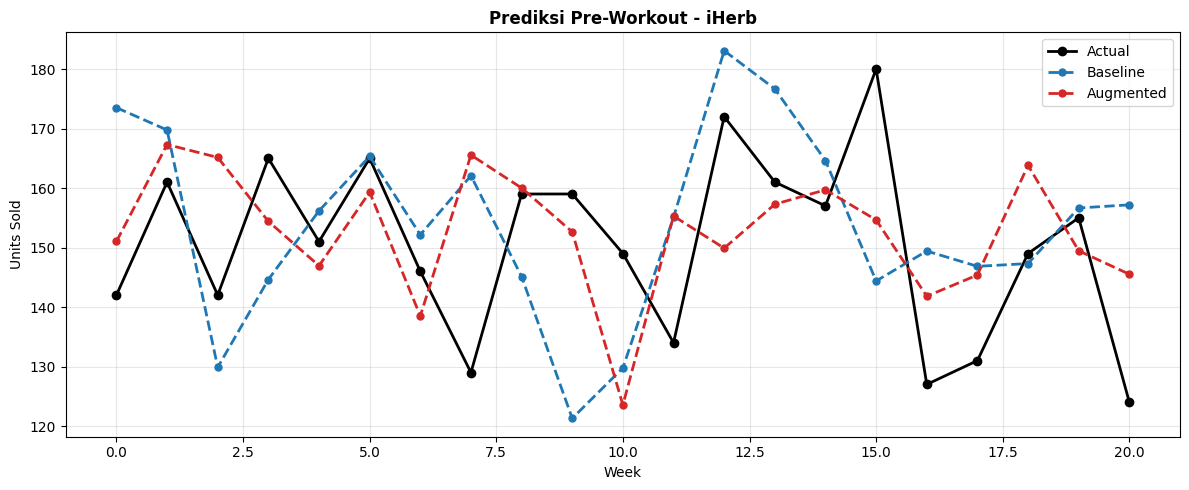

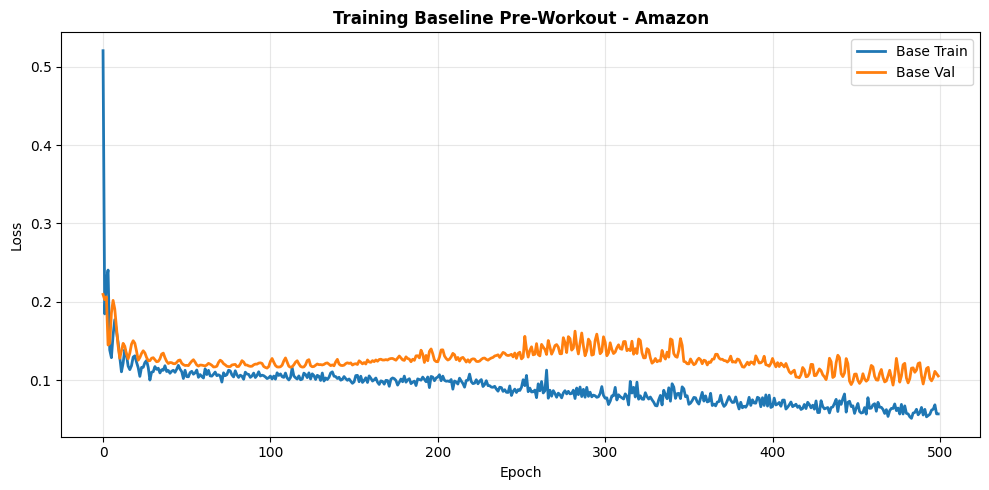

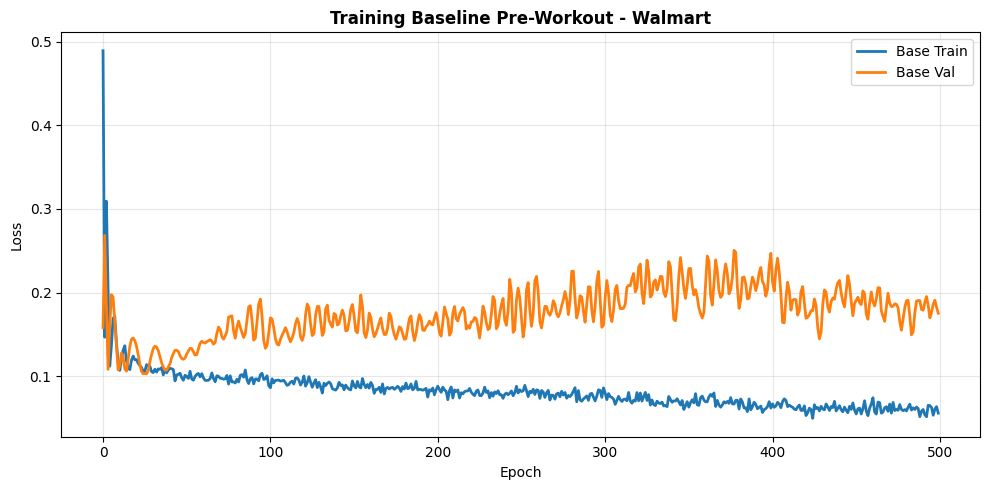

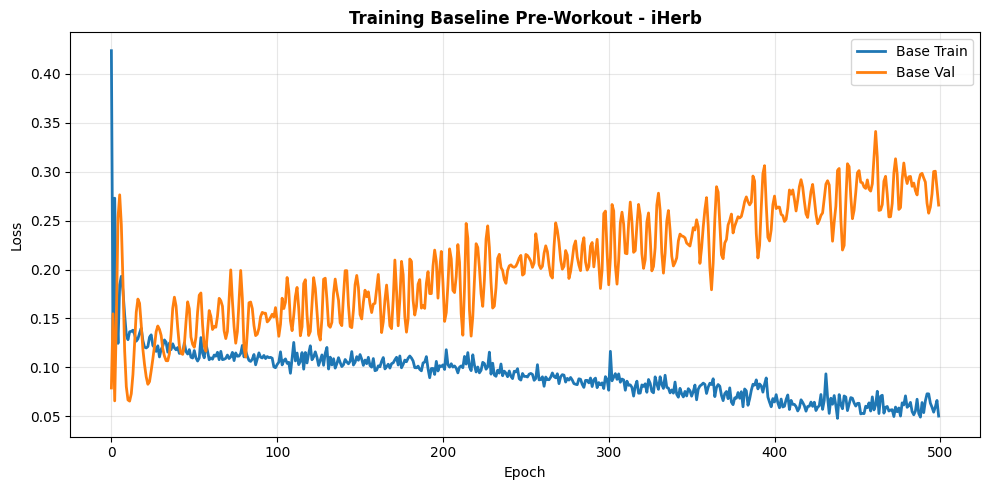

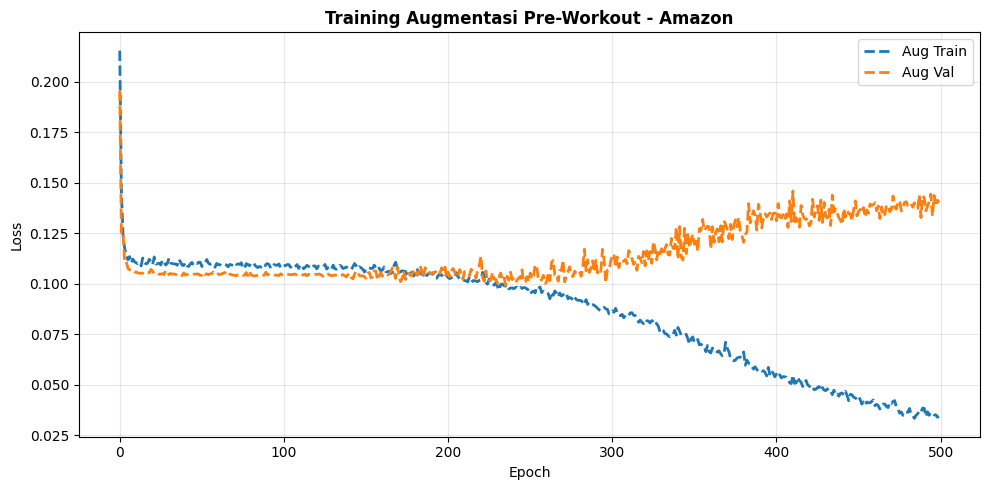

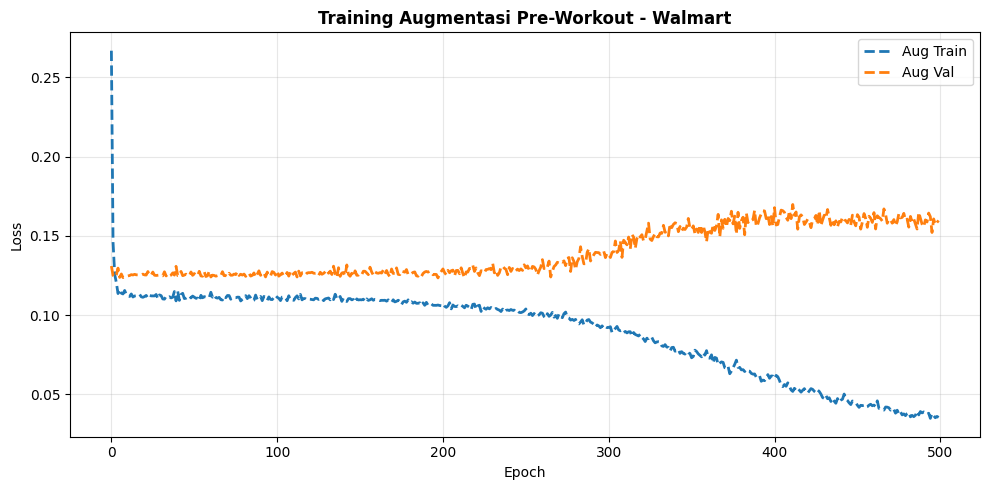

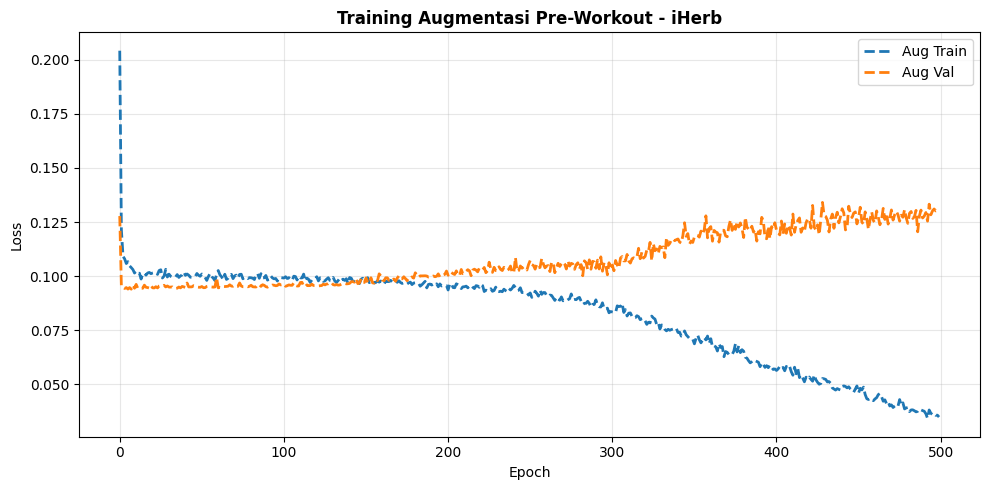

In [ ]:
# Set seed
SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def windowing(data, lag, target_col=0):
  x, y = [], []
  for i in range(lag, len(data)):
      x.append(data[i - lag:i, :])
      y.append(data[i, target_col])
  return np.array(x), np.array(y)

def GRU_train(input_shape, parameters):
  regressorGRU = Sequential()
  regressorGRU.add(GRU(units=parameters['hidden_units'], return_sequences=True, input_shape=input_shape, activation='tanh'))
  regressorGRU.add(Dropout(0.1))
  regressorGRU.add(GRU(units=parameters['hidden_units'], return_sequences=True, activation='tanh'))
  regressorGRU.add(Dropout(0.1))
  regressorGRU.add(GRU(units=parameters['hidden_units'], return_sequences=False, activation='tanh'))
  regressorGRU.add(Dropout(0.1))
  regressorGRU.add(Dense(units=1))
  regressorGRU.compile(optimizer=Adam(learning_rate=parameters['learning_rate']), loss='mean_absolute_error')
  return regressorGRU

def eval_metrics(y_true, y_pred):
  rmse = np.sqrt(mean_squared_error(y_true, y_pred))
  mape = mean_absolute_percentage_error(y_true, y_pred) * 100
  mae = mean_absolute_error(y_true, y_pred)
  return rmse, mape, mae

def inverse_transform(y_pred, scaler, col_index=0, n_features=7):
  y_pred = y_pred.reshape(-1, 1)
  dummy = np.zeros((len(y_pred), n_features))
  dummy[:, col_index] = y_pred.flatten()
  inv = scaler.inverse_transform(dummy)
  return inv[:, col_index:col_index+1]

def forecast(model, initial_window, test_data, scaler, seq_len, n_features=7):
  predictions = []
  current_window = initial_window.copy()
  for step in range(len(test_data)):
    X_input = current_window.reshape(1, seq_len, n_features)
    y_pred_norm = model.predict(X_input, verbose=0)[0, 0]
    predictions.append(y_pred_norm)

    # Update window
    new_row = np.array([
      y_pred_norm,           # Prediksi Units Sold
      test_data[step, 1],    # Actual Price
      test_data[step, 2],    # Actual Revenue
      test_data[step, 3],    # Actual Discount
      test_data[step, 4],    # Actual Units Returned
      test_data[step, 5],    # Product Encoded
      test_data[step, 6]     # Platform Encoded
    ])

    current_window = np.vstack([current_window[1:], new_row])

  predictions = np.array(predictions).reshape(-1, 1)
  predictions_inv = inverse_transform(predictions, scaler, col_index=0, n_features=n_features)
  return predictions_inv.flatten()

with open("/content/drive/MyDrive/itemL_encoder.pkl", "rb") as f:
  itemL = pickle.load(f)
with open("/content/drive/MyDrive/platL_encoder.pkl", "rb") as f:
  platL = pickle.load(f)
with open("/content/drive/MyDrive/scaler.pkl", "rb") as f:
  scaler = pickle.load(f)

item_id_to_name = {i: name for i, name in enumerate(itemL.classes_)}
plat_id_to_name = {i: name for i, name in enumerate(platL.classes_)}

n_items = len(itemL.classes_)
n_platforms = len(platL.classes_)

# Pilih item
selected_item_name = "Pre-Workout"

if selected_item_name in itemL.classes_:
    selected_item_id = itemL.transform([selected_item_name])[0]
    print(f"Selected Product: {selected_item_name} (ItemID: {selected_item_id})")
else:
    print(f"❌ Error: '{selected_item_name}' not found!")
    print(f"Available items: {list(itemL.classes_)}")
    raise ValueError(f"Item '{selected_item_name}' not found")

train_item_id = np.round(train_norm[:, 5] * (n_items - 1)).astype(int)
item_mask_train = train_item_id == selected_item_id
train_item = train_norm[item_mask_train]

test_item_id = np.round(test_norm[:, 5] * (n_items - 1)).astype(int)
item_mask_test = test_item_id == selected_item_id
test_item = test_norm[item_mask_test]

sintetis = np.load("/content/drive/MyDrive/data_sintetis.npy")
sintetis_flat = sintetis.reshape(-1, sintetis.shape[2])

synth_item_id = np.round(sintetis_flat[:, 5] * (n_items - 1)).astype(int)
item_mask_synth = synth_item_id == selected_item_id
synth_item_flat = sintetis_flat[item_mask_synth]

print(f"\nFiltered data for {selected_item_name}:")
print(f"  Train: {train_item.shape}")
print(f"  Test: {test_item.shape}")
print(f"  Synthetic: {synth_item_flat.shape}")

params = {
    'learning_rate': 0.001,
    'hidden_units': 128,
    'batch_size': 196,
    'epochs': 500
}

all_results = {}
for plat_id, plat_name in plat_id_to_name.items():
  print(f"\nTraining: {selected_item_name} - {plat_name}")
  # Filter by platform
  train_plat_ids = np.round(train_item[:, 6] * (n_platforms - 1)).astype(int)
  test_plat_ids = np.round(test_item[:, 6] * (n_platforms - 1)).astype(int)
  synth_plat_ids = np.round(synth_item_flat[:, 6] * (n_platforms - 1)).astype(int)

  plat_mask_train = train_plat_ids == plat_id
  plat_mask_test = test_plat_ids == plat_id
  plat_mask_synth = synth_plat_ids == plat_id

  train_plat = train_item[plat_mask_train]
  test_plat = test_item[plat_mask_test]
  synth_plat = synth_item_flat[plat_mask_synth]

  # Train Baseline
  print("Training Baseline Model...")
  x_train_base, y_train_base = windowing(train_plat, seq_len, target_col=0)
  x_test, y_test = windowing(test_plat, seq_len, target_col=0)
  model_base = GRU_train((x_train_base.shape[1], x_train_base.shape[2]), params)
  his_base = model_base.fit(x_train_base, y_train_base, batch_size=params['batch_size'], epochs=params['epochs'], validation_split=0.1, verbose=0)

  # Train Augmented
  print("Training Augmented Model...")
  synth_clip = np.clip(synth_plat, train_plat.min(axis=0), train_plat.max(axis=0))
  combined_train = np.vstack([train_plat, synth_clip])
  x_train_aug, y_train_aug = windowing(combined_train, seq_len, target_col=0)
  model_aug = GRU_train((x_train_aug.shape[1], x_train_aug.shape[2]), params)
  his_aug = model_aug.fit(x_train_aug, y_train_aug, batch_size=params['batch_size'], epochs=params['epochs'], validation_split=0.1, verbose=0)

  # Forecasting
  n_features = train_plat.shape[1]
  initial = train_plat[-seq_len:]
  pred_base_weekly = forecast(model_base, initial, test_plat, scaler, seq_len, n_features)
  pred_aug_weekly = forecast(model_aug, initial, test_plat, scaler, seq_len, n_features)

  y_actual_weekly = scaler.inverse_transform(test_plat)[:, 0]

  rmse_b, mape_b, mae_b = eval_metrics(y_actual_weekly, pred_base_weekly)
  rmse_a, mape_a, mae_a = eval_metrics(y_actual_weekly, pred_aug_weekly)

  # Store results
  all_results[plat_name] = {
      'product': selected_item_name,
      'platform': plat_name,
      'y_actual': y_actual_weekly,
      'pred_base': pred_base_weekly,
      'pred_aug': pred_aug_weekly,
      'metrics_base': {'RMSE': rmse_b, 'MAPE': mape_b, 'MAE': mae_b},
      'metrics_aug': {'RMSE': rmse_a, 'MAPE': mape_a, 'MAE': mae_a},
      'history_base': his_base,
      'history_aug': his_aug
  }

all_actual = []
all_pred_base = []
all_pred_aug = []

for platform_name, result in all_results.items():
  all_actual.extend(result['y_actual'])
  all_pred_base.extend(result['pred_base'])
  all_pred_aug.extend(result['pred_aug'])

all_actual = np.array(all_actual)
all_pred_base = np.array(all_pred_base)
all_pred_aug = np.array(all_pred_aug)

overall_rmse_b, overall_mape_b, overall_mae_b = eval_metrics(all_actual, all_pred_base)
overall_rmse_a, overall_mape_a, overall_mae_a = eval_metrics(all_actual, all_pred_aug)

summary_data = []
for platform_name, result in all_results.items():
  row = {
      'Platform': result['platform'],
      'Base_MAPE': f"{result['metrics_base']['MAPE']:.2f}%",
      'Base_MAE': f"{result['metrics_base']['MAE']:.2f}",
      'Base_RMSE': f"{result['metrics_base']['RMSE']:.2f}",
      'Aug_MAPE': f"{result['metrics_aug']['MAPE']:.2f}%",
      'Aug_MAE': f"{result['metrics_aug']['MAE']:.2f}",
      'Aug_RMSE': f"{result['metrics_aug']['RMSE']:.2f}",
  }
  summary_data.append(row)
overall_row = {
        'Platform': 'OVERALL',
        'Base_MAPE': f"{overall_mape_b:.2f}%",
        'Base_MAE': f"{overall_mae_b:.2f}",
        'Base_RMSE': f"{overall_rmse_b:.2f}",
        'Aug_MAPE': f"{overall_mape_a:.2f}%",
        'Aug_MAE': f"{overall_mae_a:.2f}",
        'Aug_RMSE': f"{overall_rmse_a:.2f}",
    }
summary_data.append(overall_row)

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

summary_df.to_csv(f"/content/drive/MyDrive/forecast_summary_{selected_item_name}.csv", index=False)

# Plot Prediksi
for platform_name, result in all_results.items():
  plt.figure(figsize=(12, 5))
  plt.plot(result['y_actual'], 'o-', color='black', label='Actual', linewidth=2, markersize=6)
  plt.plot(result['pred_base'], 'o--', color='#1f77b4', label='Baseline', linewidth=2, markersize=5)
  plt.plot(result['pred_aug'], 'o--', color='#d62728', label='Augmented', linewidth=2, markersize=5)
  plt.title(f"Prediksi {result['product']} - {platform_name}", fontsize=12, fontweight='bold')
  plt.xlabel('Week')
  plt.ylabel('Units Sold')
  plt.legend()
  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.savefig(f"/content/drive/MyDrive/prediksi_{selected_item_name}_{platform_name}.png", dpi=150, bbox_inches='tight')
  plt.show()

# Plot Training Base
for platform_name, result in all_results.items():
  plt.figure(figsize=(10, 5))
  plt.plot(result['history_base'].history['loss'], label='Base Train', linewidth=2)
  plt.plot(result['history_base'].history['val_loss'], label='Base Val', linewidth=2)
  plt.title(f'Training Baseline {result["product"]} - {platform_name}', fontsize=12, fontweight='bold')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.legend()
  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.savefig(f"/content/drive/MyDrive/history_base_{selected_item_name}_{platform_name}.png", dpi=150, bbox_inches='tight')
  plt.show()

#Plot Training Augmentasi
for platform_name, result in all_results.items():
  plt.figure(figsize=(10, 5))
  plt.plot(result['history_aug'].history['loss'], label='Aug Train', linewidth=2, linestyle='--')
  plt.plot(result['history_aug'].history['val_loss'], label='Aug Val', linewidth=2, linestyle='--')
  plt.title(f'Training Augmentasi {result["product"]} - {platform_name}', fontsize=12, fontweight='bold')
  plt.xlabel('Epoch')
  plt.ylabel('Loss')
  plt.legend()
  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.savefig(f"/content/drive/MyDrive/history_aug_{selected_item_name}_{platform_name}.png", dpi=150, bbox_inches='tight')
  plt.show()

In [ ]:
# untuk liat jumlah data sintetis yg dihasilkan
with open("/content/drive/MyDrive/itemL_encoder.pkl", "rb") as f:
  itemL = pickle.load(f)
with open("/content/drive/MyDrive/platL_encoder.pkl", "rb") as f:
  platL = pickle.load(f)
with open("/content/drive/MyDrive/scaler.pkl", "rb") as f:
  scaler = pickle.load(f)

item_id_to_name = {i: name for i, name in enumerate(itemL.classes_)}
plat_id_to_name = {i: name for i, name in enumerate(platL.classes_)}

n_items = len(itemL.classes_)
n_platforms = len(platL.classes_)

# Pilih item
selected_item_name = "Zinc"

if selected_item_name in itemL.classes_:
    selected_item_id = itemL.transform([selected_item_name])[0]
    print(f"Selected Product: {selected_item_name} (ItemID: {selected_item_id})")
else:
    print(f"❌ Error: '{selected_item_name}' not found!")
    print(f"Available items: {list(itemL.classes_)}")
    raise ValueError(f"Item '{selected_item_name}' not found")

train_item_id = np.round(train_norm[:, 5] * (n_items - 1)).astype(int)
item_mask_train = train_item_id == selected_item_id
train_item = train_norm[item_mask_train]

test_item_id = np.round(test_norm[:, 5] * (n_items - 1)).astype(int)
item_mask_test = test_item_id == selected_item_id
test_item = test_norm[item_mask_test]

sintetis = np.load("/content/drive/MyDrive/data_sintetis.npy")
sintetis_flat = sintetis.reshape(-1, sintetis.shape[2])

synth_item_id = np.round(sintetis_flat[:, 5] * (n_items - 1)).astype(int)
item_mask_synth = synth_item_id == selected_item_id
synth_item_flat = sintetis_flat[item_mask_synth]

print(f"\nDetail Data {selected_item_name}:")
print(f"  Data Latih: {train_item.shape[0]} Baris")
print(f"  Data Uji: {test_item.shape[0]} Baris")
print(f"  Data Sintetis: {synth_item_flat.shape[0]} Baris")
print("\nItem | Platform | Train | Synth | Aug | Test")
print("-" * 50)

for plat_id, plat_name in plat_id_to_name.items():
  #print(f"\nKombinasi: {selected_item_name} - {plat_name}")
  # Filter by platform
  train_plat_ids = np.round(train_item[:, 6] * (n_platforms - 1)).astype(int)
  test_plat_ids = np.round(test_item[:, 6] * (n_platforms - 1)).astype(int)
  synth_plat_ids = np.round(synth_item_flat[:, 6] * (n_platforms - 1)).astype(int)

  plat_mask_train = train_plat_ids == plat_id
  plat_mask_test = test_plat_ids == plat_id
  plat_mask_synth = synth_plat_ids == plat_id

  train_plat = train_item[plat_mask_train]
  test_plat = test_item[plat_mask_test]
  synth_plat = synth_item_flat[plat_mask_synth]

  synth_clip = np.clip(synth_plat, train_plat.min(axis=0), train_plat.max(axis=0))
  combined_train = np.vstack([train_plat, synth_clip])
  # print(f"Data Latih: {train_plat.shape[0]} Baris")
  # print(f"Data Sintetis: {synth_plat.shape[0]} Baris")
  # print(f"Data Augmentasi: {combined_train.shape[0]} Baris")
  # print(f"Data Uji: {test_plat.shape[0]} Baris")


  print(f"{selected_item_name:12s} | {plat_name:8s} | "
        f"{train_plat.shape[0]:5d} | "
        f"{synth_plat.shape[0]:5d} | "
        f"{combined_train.shape[0]:5d} | "
        f"{test_plat.shape[0]:5d}")


Selected Product: Zinc (ItemID: 15)

Detail Data Zinc:
  Data Latih: 219 Baris
  Data Uji: 55 Baris
  Data Sintetis: 1541 Baris

Item | Platform | Train | Synth | Aug | Test
--------------------------------------------------
Zinc         | Amazon   |    67 |   346 |   413 |    26
Zinc         | Walmart  |    77 |   621 |   698 |    11
Zinc         | iHerb    |    75 |   574 |   649 |    18
